<a href="https://colab.research.google.com/github/silviacatellani05-hash/DAT105-Gallstone/blob/main/Gallstones.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Can machine learning models provide reliable gallstone probabilities for new patients, and which features drive these probabilities?**


In [13]:
   !unzip -o gallstone.zip
   !unzip -o dataset-uci.zip
   !ls
   !ls -l dataset-uci.xlsx
   !pip install python-calamine

unzip:  cannot find or open gallstone.zip, gallstone.zip.zip or gallstone.zip.ZIP.
unzip:  cannot find or open dataset-uci.zip, dataset-uci.zip.zip or dataset-uci.zip.ZIP.
sample_data
ls: cannot access 'dataset-uci.xlsx': No such file or directory


In [ ]:
import pandas as pd
df = pd.read_excel("dataset-uci.xlsx", engine="calamine")
df.shape # prints shape of excel table


(319, 39)

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# 1. Separate features (X) from the target diagnosis variable (y)
target_col = 'Gallstone Status' if 'Gallstone Status' in df.columns else df.columns[-1]

X = df.drop(columns=[target_col])
y = df[target_col]

print(f"Feature Matrix (X): {X.shape}")
print(f"Target Variable (y): {y.shape}")
print("\nClass distribution (0 = Present, 1 = Absent):")
print(y.value_counts())

# 2. Split dataset into Training (80%) and Testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Train the Random Forest Classifier
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

# 4. Evaluate model Accuracy on the test set
y_pred = model.predict(X_test)
print(f"\nRandom Forest Model Accuracy: {accuracy_score(y_test, y_pred):.4f}")

# 5. Feature Importance ranking (Explainable AI - XAI)
feature_importance = pd.Series(model.feature_importances_, index=X.columns)
print("\nTop 5 Most Important Clinical Features:")
print(feature_importance.sort_values(ascending=False).head(5))

Feature Matrix (X): (319, 38)
Target Variable (y): (319,)

Class distribution (0 = Present, 1 = Absent):
Gallstone Status
0    161
1    158
Name: count, dtype: int64

Random Forest Model Accuracy: 0.7969

Top 5 Most Important Clinical Features:
C-Reactive Protein (CRP)                          0.134276
Vitamin D                                         0.100427
Extracellular Water (ECW)                         0.043081
Extracellular Fluid/Total Body Water (ECF/TBW)    0.041774
Aspartat Aminotransferaz (AST)                    0.039073
dtype: float64


In [ ]:
#how many patients
print("rows and columns: ", df.shape)

#names of the variables:
print("columns: ")
print(df.columns.tolist())

print("unhealthy and healthy patients: ")
print(df['Gallstone Status'].value_counts())

rows and columns:  (319, 39)
columns: 
['Gallstone Status', 'Age', 'Gender', 'Comorbidity', 'Coronary Artery Disease (CAD)', 'Hypothyroidism', 'Hyperlipidemia', 'Diabetes Mellitus (DM)', 'Height', 'Weight', 'Body Mass Index (BMI)', 'Total Body Water (TBW)', 'Extracellular Water (ECW)', 'Intracellular Water (ICW)', 'Extracellular Fluid/Total Body Water (ECF/TBW)', 'Total Body Fat Ratio (TBFR) (%)', 'Lean Mass (LM) (%)', 'Body Protein Content (Protein) (%)', 'Visceral Fat Rating (VFR)', 'Bone Mass (BM)', 'Muscle Mass (MM)', 'Obesity (%)', 'Total Fat Content (TFC)', 'Visceral Fat Area (VFA)', 'Visceral Muscle Area (VMA) (Kg)', 'Hepatic Fat Accumulation (HFA)', 'Glucose', 'Total Cholesterol (TC)', 'Low Density Lipoprotein (LDL)', 'High Density Lipoprotein (HDL)', 'Triglyceride', 'Aspartat Aminotransferaz (AST)', 'Alanin Aminotransferaz (ALT)', 'Alkaline Phosphatase (ALP)', 'Creatinine', 'Glomerular Filtration Rate (GFR)', 'C-Reactive Protein (CRP)', 'Hemoglobin (HGB)', 'Vitamin D']
unhealt

<function matplotlib.pyplot.show(close=None, block=None)>

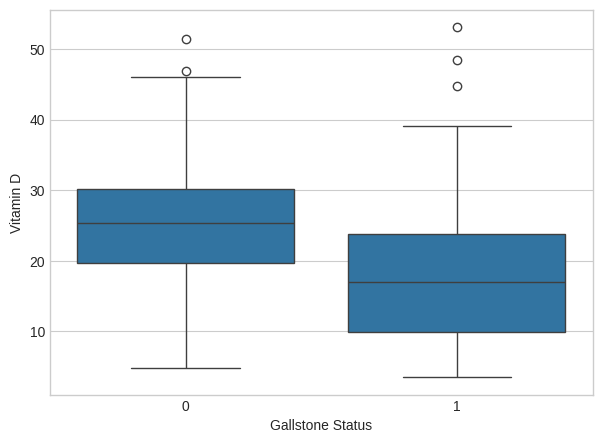

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

vit_col = [col for col in df.columns if 'Vit' in col or 'vit' in col][0]
plt.figure(figsize=(7,5))
sns.boxplot(data = df, x = 'Gallstone Status', y = vit_col)
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

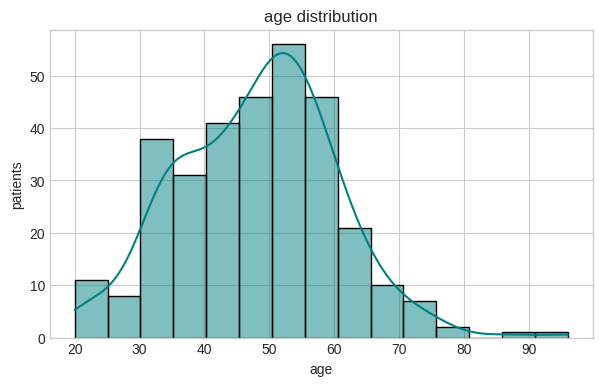

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize = (7,4))

sns.histplot(data=df, x='Age', kde=True, color='teal')

plt.title('age distribution')
plt.xlabel('age')
plt.ylabel('patients')
plt.show

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Carica il dataframe se non è presente in memoria
if 'df' not in locals():
    df = pd.read_excel("dataset-uci.xlsx", engine="calamine")

crp_col = [c for c in df.columns if 'BMI' in c][0]

plt.figure(figsize=(6,4))
sns.boxplot(data=df, x='Gallstone Status', y=crp_col, palette='Set1')

plt.title('BMI: healthy vs gallstone')
plt.xlabel('Gallstone Status')
plt.ylabel('BMI')
plt.show()

NameError: name 'df' is not defined